In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
import torch
from torch import nn
from IPython.display import clear_output, display

# The physical problem

A rod with fixed, zero-temperature ends. In dimensionless variables,
$$
\frac{\partial u}{\partial t}
= \alpha \frac{\partial^2 u}{\partial x^2},
\qquad x \in [0,1], \quad t \in [0,1],
\qquad \alpha = 0.1.
$$

The initial and boundary conditions are

$$
u(x,0) = \sin(\pi x), \qquad
u(0,t) = u(1,t) = 0.
$$

### Analytical Solution

$$
\boxed{u(x,t) = \sin(\pi x)e^{-0.1\pi^2t}}
$$


### Four milestones:
1. Generate and verify an analytical reference.
2. Build a network $u_\theta(x,t)$ and compute its input derivatives.
3. Train it using temperature observations, the PDE, and initial and boundary conditions.
4. Evaluate its error at points withheld from training.


In [2]:
# The analytical solution

alpha = 0.1
def u_exact(x,t):
    return np.sin(np.pi*x)*np.exp(-alpha*np.pi**2*t)

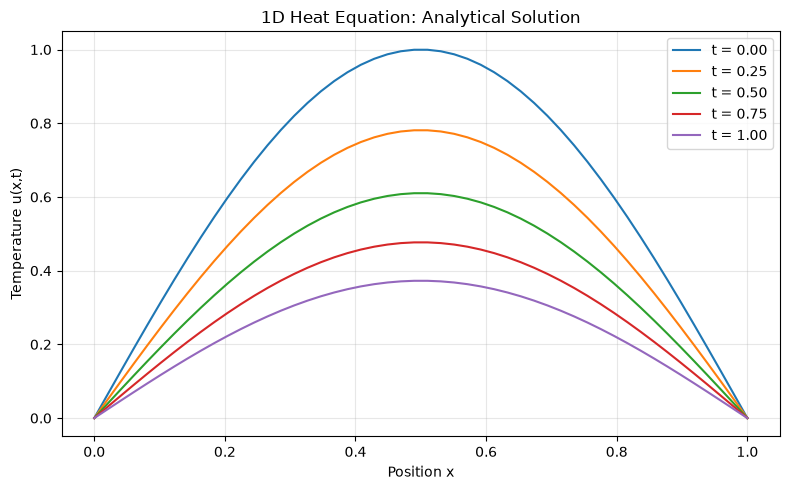

In [3]:
#Plotting the analytical solution

x = np.linspace(0, 1, 50)
times = [0.0, 0.25, 0.5, 0.75, 1.0]

plt.figure(figsize=(8,5))

for t in times:
    plt.plot(x, u_exact(x, t), label=f"t = {t:.2f}")
    
plt.xlabel("Position x")
plt.ylabel("Temperature u(x,t)")
plt.title("1D Heat Equation: Analytical Solution")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# sampling points

x_obs = rng.uniform(0, 1, size=(128, 1))
t_obs = rng.uniform(0, 1, size=(128, 1))

xt_obs = np.concatenate((x_obs, t_obs), axis=1)
u_obs = u_exact(x_obs, t_obs)

print(u_obs.shape)  # (128, 1)

print(xt_obs.shape)  # should be (128, 2)
print(xt_obs[:5])

(128, 1)
(128, 2)
[[0.81656876 0.37635947]
 [0.10527808 0.98663154]
 [0.06655886 0.71776024]
 [0.59443366 0.95119466]
 [0.14617324 0.11847858]]


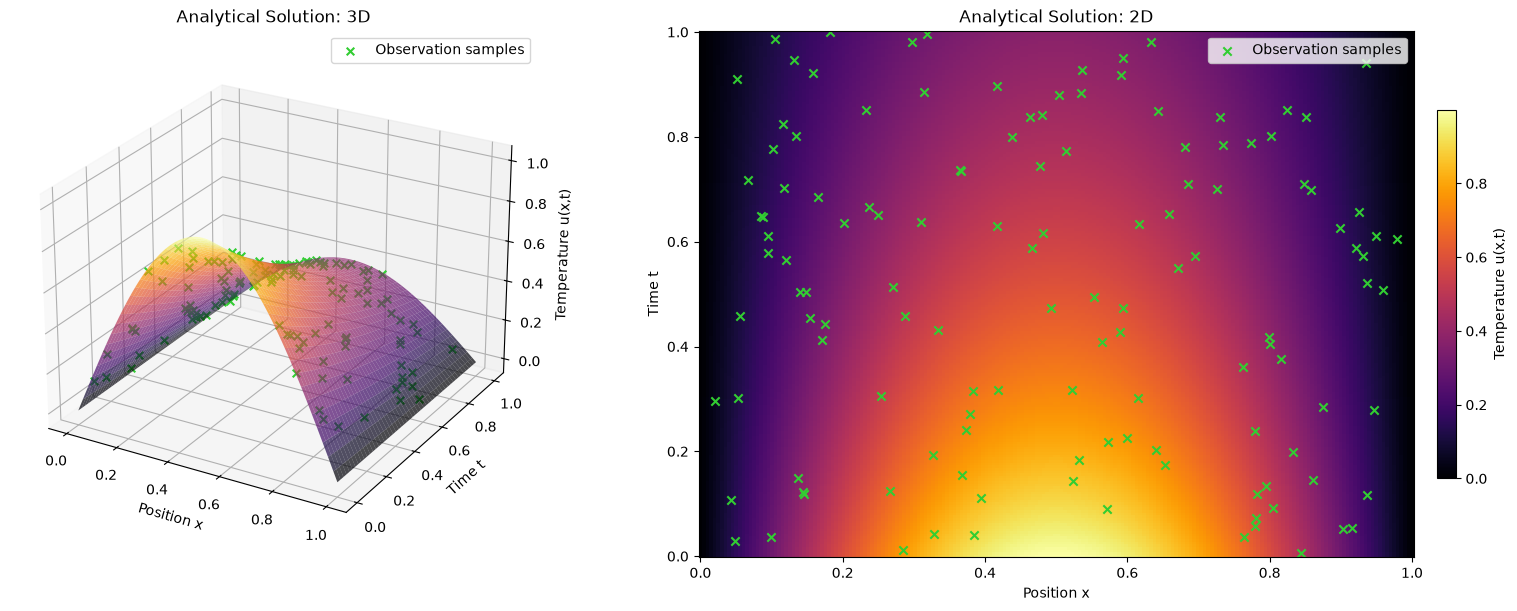

In [6]:
# plotting the sampled points on the analytical solution field

x = np.linspace(0, 1, 200)
t = np.linspace(0, 1, 200)
X, T = np.meshgrid(x, t)
U = u_exact(X, T)

fig = plt.figure(figsize=(16, 6), layout="constrained")

# 3D surface
ax1 = fig.add_subplot(1, 2, 1, projection="3d")

surface = ax1.plot_surface(X, T, U, cmap="inferno", alpha=0.7)
ax1.scatter(
    x_obs.ravel(),
    t_obs.ravel(),
    u_obs.ravel(),
    color="limegreen",
    marker="x",
    s=30,
    depthshade=False,
    label="Observation samples",
)

ax1.set_xlabel("Position x")
ax1.set_ylabel("Time t")
ax1.set_zlabel("Temperature u(x,t)")
ax1.set_title("Analytical Solution: 3D")
ax1.view_init(elev=25, azim=-60)
ax1.legend(loc="upper right")

# fig.colorbar(surface, ax=ax1, shrink=0.7, pad=0.1, label="Temperature u(x,t)")

# 2D field
ax2 = fig.add_subplot(1, 2, 2)

field = ax2.pcolormesh(X, T, U, shading="auto", cmap="inferno")
ax2.scatter(
    x_obs.ravel(),
    t_obs.ravel(),
    color="limegreen",
    marker="x",
    label="Observation samples",
)

ax2.set_xlabel("Position x")
ax2.set_ylabel("Time t")
ax2.set_title("Analytical Solution: 2D")
ax2.legend(loc="upper right")

fig.colorbar(field, ax=ax2, shrink=0.7, pad=0.02, label="Temperature u(x,t)")

plt.show()

In [7]:
## Sampling initial conditions

# rng = np.random.default_rng(42)

x_init = rng.uniform(0, 1, size=(64, 1))
t_init = np.zeros((64, 1)) #rng.uniform(0, 1, size=(128, 1))
u_init = np.sin(np.pi*x_init)

xt_init = np.concatenate((x_init, t_init), axis=1)
print(xt_init.shape)  # should be (64, 2)
print("(x_init, t_init) =", xt_init[:5])
print("u_init=", u_init[:5])

## Sampling left boundary conditions
# rng = np.random.default_rng(42)

x_leftBC = np.zeros((64,1)) # rng.uniform(0, 1, size=(64, 1))
t_leftBC = rng.uniform(0, 1, size=(64, 1))
u_leftBC = np.zeros((64,1))

xt_leftBC = np.concatenate((x_leftBC, t_leftBC), axis=1)
print(xt_leftBC.shape)  # should be (64, 2)
print("(x_leftBC, t_leftBC) =", xt_leftBC[:5])
print("u_leftBC=", u_leftBC[:5])


## Sampling right boundary conditions


x_rightBC = np.ones((64,1)) # rng.uniform(0, 1, size=(64, 1))
t_rightBC = rng.uniform(0, 1, size=(64, 1))
u_rightBC = np.zeros((64,1))

xt_rightBC = np.concatenate((x_rightBC, t_rightBC), axis=1)
print(xt_rightBC.shape)  # should be (64, 2)
print("(x_rightBC, t_rightBC) =", xt_rightBC[:5])
print("u_rightBC=", u_rightBC[:5])

(64, 2)
(x_init, t_init) = [[0.05556792 0.        ]
 [0.28061144 0.        ]
 [0.33413004 0.        ]
 [0.17299445 0.        ]
 [0.31389337 0.        ]]
u_init= [[0.17368642]
 [0.77173624]
 [0.86727415]
 [0.51711605]
 [0.83389359]]
(64, 2)
(x_leftBC, t_leftBC) = [[0.         0.90955224]
 [0.         0.58712394]
 [0.         0.8502743 ]
 [0.         0.3405908 ]
 [0.         0.49881696]]
u_leftBC= [[0.]
 [0.]
 [0.]
 [0.]
 [0.]]
(64, 2)
(x_rightBC, t_rightBC) = [[1.         0.73943147]
 [1.         0.80087159]
 [1.         0.04896371]
 [1.         0.23453515]
 [1.         0.62189777]]
u_rightBC= [[0.]
 [0.]
 [0.]
 [0.]
 [0.]]


In [8]:
## Sampling PDE collocation points


x_PDE = rng.uniform(0, 1, size=(1024, 1))
t_PDE = rng.uniform(0, 1, size=(1024, 1))


xt_PDE = np.concatenate((x_PDE, t_PDE), axis=1)
print(xt_PDE.shape)  # should be (64, 2)
print("(x_PDE, t_PDE) =", xt_PDE[:5])

(1024, 2)
(x_PDE, t_PDE) = [[0.28324693 0.03089284]
 [0.56148939 0.39643624]
 [0.79197443 0.94514829]
 [0.78382411 0.05088073]
 [0.43838626 0.74970575]]


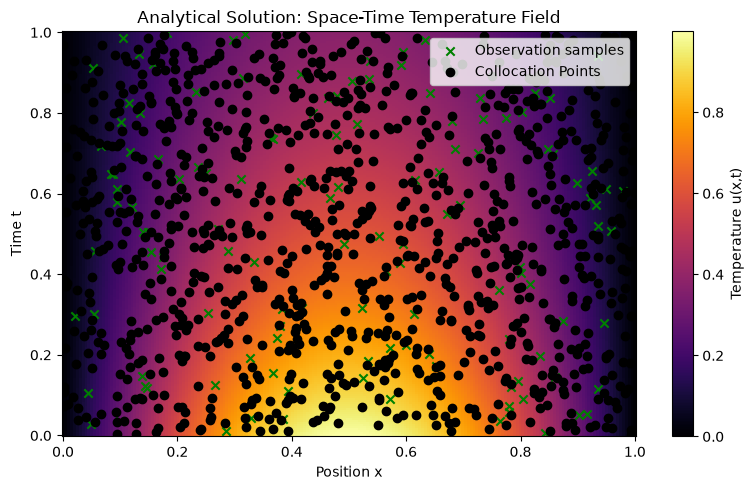

In [9]:
x = np.linspace(0, 1, 200)
t = np.linspace(0,1,200)

X, T = np.meshgrid(x,t)

U = u_exact(X, T)


plt.figure(figsize=(8,5))
plt.pcolormesh(X, T, U, shading="auto", cmap="inferno")

plt.colorbar(label="Temperature u(x,t)")

plt.scatter(x_obs, t_obs, c="green", marker="x", label="Observation samples")
plt.scatter(x_PDE, t_PDE, c="black", marker="o", label="Collocation Points")
plt.legend(loc="upper right")
plt.xlabel("Position x")
plt.ylabel("Time t")
plt.title("Analytical Solution: Space-Time Temperature Field")
plt.tight_layout()
plt.show()

#### At an observation point, the error is

$$
\underbrace{u_\theta(x_i,t_i)}_{\text{network prediction}}
-
\underbrace{u_{\text{exact}}(x_i,t_i)}_{\text{known temperature}}
$$

#### Error at a Collocation Point


$$
\underbrace{
u_{\theta,t}(x_j,t_j)
-
0.1u_{\theta,xx}(x_j,t_j)
}_{\text{PDE residual}}
$$



**Both `xt_obs` and `xt_PDE` are interior points.** “Interior” tells you **where** a point is. “Observation” and “collocation” tell you **what you check** there.

Take one point, say \((x,t)=(0.5,0.5)\). Suppose your network predicts the exact temperature there, but its derivatives at that point are \(u_t=+0.2\) and \(u_{xx}=-2\).

| Use that point as… | What happens? |
| --- | --- |
| An **observation** | It passes. The predicted temperature matches the known value. |
| A **PDE collocation point** | It fails. The curvature requires \(u_t=0.1(-2)=-0.2\), but the network predicts \(+0.2\). |

So the network can get the **temperature right at a point** while getting the **local evolution wrong**. That’s what the PDE loss catches.

The same coordinate can serve both roles. We sample extra collocation points so we can check the heat equation at more locations using only \([x,t]\). The boundary points at \(x=0,1\) and initial points at \(t=0\) supply prescribed **temperature values**, just as observations do.


In [10]:
#Converting to tensors

xt_obs_t = torch.tensor(xt_obs, dtype=torch.float32)
u_obs_t = torch.tensor(u_obs, dtype=torch.float32)

xt_PDE_t = torch.tensor(xt_PDE, dtype=torch.float32)
xt_PDE_t.requires_grad_(True)

xt_leftBC_t = torch.tensor(xt_leftBC, dtype=torch.float32)
xt_rightBC_t = torch.tensor(xt_rightBC, dtype=torch.float32)
xt_init_t = torch.tensor(xt_init, dtype=torch.float32)

u_leftBC_t = torch.tensor(u_leftBC, dtype=torch.float32)
u_rightBC_t = torch.tensor(u_rightBC, dtype=torch.float32)
u_init_t = torch.tensor(u_init, dtype=torch.float32)


In [11]:
torch.manual_seed(42)

class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.network = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,1)
        )
        
    def forward(self, xt):
            return self.network(xt)

In [12]:
model = PINN()

test_input = xt_obs_t[:7]
test_output = model(test_input)

print(test_input.shape)   

print(test_output.shape) 

assert test_output.shape == (7, 1)


torch.Size([7, 2])
torch.Size([7, 1])


# Computing derivatives:

learn to compute derivatives with respect to the inputs. We need these to construct the PDE residual at the collocation points: $u_t$ and $u_{xx}$

In [13]:
# Predict temperature at the PDE collocation points
u_pred_PDE = model(xt_PDE_t)  # (1024, 1)


# Differentiate predicted temperature with respect to [x, t]
du_dxt = torch.autograd.grad(
    outputs = u_pred_PDE, 
    inputs = xt_PDE_t,
    grad_outputs=torch.ones_like(u_pred_PDE),
    create_graph=True
)[0] # (1024, 2)

u_x = du_dxt[:, 0:1]  # Spatial derivative
u_t = du_dxt[:, 1:2]  # Time derivative

# Differentiate u_x with respect to [x, t]
dux_dxt = torch.autograd.grad(
    outputs=u_x,
    inputs=xt_PDE_t,
    grad_outputs=torch.ones_like(u_x),
    create_graph=True,
)[0]

u_xx = dux_dxt[:, 0:1]  # Second spatial derivative

# Heat-equation residual
residual_PDE = u_t - alpha * u_xx

print("u_pred_PDE:", u_pred_PDE.shape)
print("du_dxt:", du_dxt.shape)
print("u_t:", u_t.shape)
print("u_xx:", u_xx.shape)
print("residual_PDE:", residual_PDE.shape)

u_pred_PDE: torch.Size([1024, 1])
du_dxt: torch.Size([1024, 2])
u_t: torch.Size([1024, 1])
u_xx: torch.Size([1024, 1])
residual_PDE: torch.Size([1024, 1])


Next, turn `residual_PDE` into a scalar loss.

At each collocation point, the desired residual is zero. A natural choice is the mean squared residual:

$$
\mathcal{L}_{\text{PDE}}
=
\frac{1}{N_{\text{PDE}}}
\sum_{i=1}^{N_{\text{PDE}}}
r_\theta(x_i,t_i)^2.
$$

Squaring prevents positive and negative residuals from cancelling. Taking the mean gives one scalar regardless of how many points we sampled.

In [15]:
# turn the residual_PDE into a scalar loss
loss_PDE = torch.mean(residual_PDE**2)

# construct observation loss
residual_obs = model(xt_obs_t) - u_obs_t
loss_obs = torch.mean(residual_obs**2)

# construct IC loss
residual_ic = model(xt_init_t) - u_init_t
loss_ic = torch.mean(residual_ic**2)

# construct leftBC loss
residual_leftBC = model(xt_leftBC_t) - u_leftBC_t
loss_leftBC = torch.mean(residual_leftBC**2)

# construct rightBC loss
residual_rightBC = model(xt_rightBC_t) - u_rightBC_t
loss_rightBC = torch.mean(residual_rightBC**2)

#combined boundary loss
loss_BC = (loss_leftBC + loss_rightBC) / 2

In [16]:
print("PDE_loss = ", loss_PDE)
print("Obs_loss = ", loss_obs)
print("IC_loss = ", loss_ic)
print("leftBC_loss = ", loss_leftBC)
print("rightBC_loss = ", loss_rightBC)
print("BC_loss = ", loss_BC)

PDE_loss =  tensor(5.6802e-05, grad_fn=<MeanBackward0>)
Obs_loss =  tensor(1.7129e-06, grad_fn=<MeanBackward0>)
IC_loss =  tensor(4.7398e-06, grad_fn=<MeanBackward0>)
leftBC_loss =  tensor(4.9668e-06, grad_fn=<MeanBackward0>)
rightBC_loss =  tensor(3.6816e-05, grad_fn=<MeanBackward0>)
BC_loss =  tensor(2.0891e-05, grad_fn=<DivBackward0>)


In [17]:
loss_fn = loss_obs + loss_PDE + loss_ic + loss_BC
# optimizer1 = torch.optim.Adam(model.parameters(),
#                              lr = 1e-3)

In [18]:
loss_fn

tensor(8.4146e-05, grad_fn=<AddBackward0>)

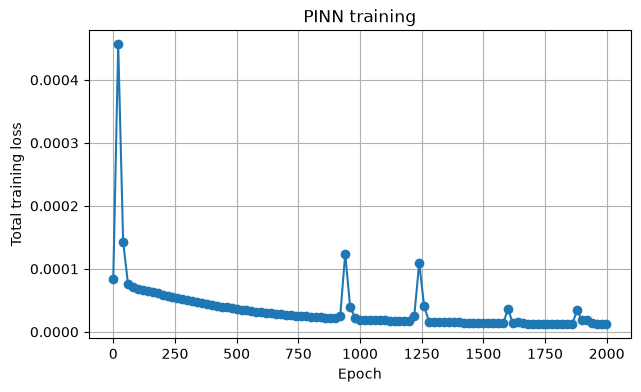

Epoch 1999 | Total: 0.0000 | PDE: 0.0000 | Obs: 0.0000 | IC: 0.0000 | BC: 0.0000


In [19]:
# Training loop

optimizer1 = torch.optim.Adam(model.parameters(),
                             lr = 1e-3)

torch.manual_seed(42)
epochs = 2000
train_loss_values = []
test_loss_values = []
epoch_count = []

loss_components = {
    "PDE": [],
    "Observation": [],
    "Initial": [],
    "Boundary": [],
}
for epoch in range(epochs):
    model.train()   
    optimizer1.zero_grad()
    # 1. Predict temperature at the collocation points
    u_pred_PDE = model(xt_PDE_t)

    # 2. First derivatives with respect to x and t
    du_dxt = torch.autograd.grad(
        outputs=u_pred_PDE,
        inputs=xt_PDE_t,
        grad_outputs=torch.ones_like(u_pred_PDE),
        create_graph=True,
    )[0]

    u_x = du_dxt[:, 0:1]
    u_t = du_dxt[:, 1:2]

    # 3. Second derivative with respect to x
    dux_dxt = torch.autograd.grad(
        outputs=u_x,
        inputs=xt_PDE_t,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True,
    )[0]

    u_xx = dux_dxt[:, 0:1]

    # 4. Heat-equation residual
    residual_PDE = u_t - alpha * u_xx

    # Calculate all losses using the current model
    loss_PDE = torch.mean(residual_PDE**2)

    residual_obs = model(xt_obs_t) - u_obs_t
    loss_obs = torch.mean(residual_obs**2)

    residual_ic = model(xt_init_t) - u_init_t
    loss_ic = torch.mean(residual_ic**2)

    residual_leftBC = model(xt_leftBC_t) - u_leftBC_t
    loss_leftBC = torch.mean(residual_leftBC**2)

    residual_rightBC = model(xt_rightBC_t) - u_rightBC_t
    loss_rightBC = torch.mean(residual_rightBC**2)

    loss_BC = (loss_leftBC + loss_rightBC) / 2

    loss = loss_obs + loss_PDE + loss_ic + loss_BC

    loss.backward()

    loss_components["PDE"].append(loss_PDE.item())
    loss_components["Observation"].append(loss_obs.item())
    loss_components["Initial"].append(loss_ic.item())
    loss_components["Boundary"].append(loss_BC.item())
    # 5. optim
    optimizer1.step()

    if epoch % 20 == 0 or epoch == epochs - 1:
        # Store the current loss as a regular Python number
        epoch_count.append(epoch)
        train_loss_values.append(loss.item())

        # Replace the previous output from this cell
        clear_output(wait=True)

        # Draw the loss history
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(epoch_count, train_loss_values, marker="o")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Total training loss")
        ax.set_title("PINN training")
        ax.grid(True)

        display(fig)
        plt.close(fig)

        print(
            f"Epoch {epoch:3d} | "
            f"Total: {loss.item():.4f} | "
            f"PDE: {loss_PDE.item():.4f} | "
            f"Obs: {loss_obs.item():.4f} | "
            f"IC: {loss_ic.item():.4f} | "
            f"BC: {loss_BC.item():.4f}"
        )


        


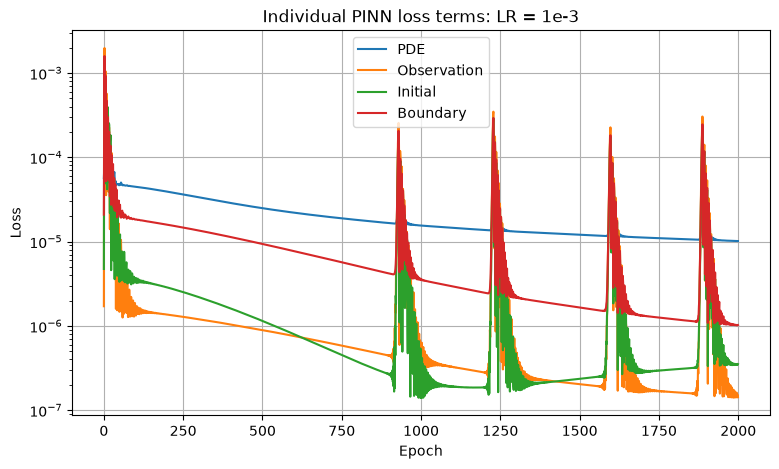

In [20]:
plt.figure(figsize=(9, 5))

for name, values in loss_components.items():
    plt.semilogy(values, label=name)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Individual PINN loss terms: LR = 1e-3")
plt.grid(True)
plt.legend()
plt.show()

## Controlled experiment: learning rate

Train separate PINNs at learning rates **0.05**, **1e-3**, and **1e-6**, for **2000 epochs each**. All runs reuse the existing observation, initial-condition, boundary, and PDE collocation tensors, with the same four loss weights.

Matching initial weights removes initialization as a source of differences. A fresh Adam optimizer starts each run without momentum from earlier training. Only the learning rate changes.

Loss histories contain values before each update. The relative $L^2$ error uses the final model on one fixed evaluation grid:

$$
\frac{\|u_\theta - u_{\mathrm{exact}}\|_2}{\|u_{\mathrm{exact}}\|_2}.
$$

In [25]:
from copy import deepcopy

learning_rates = (0.05, 1e-3, 1e-6)
experiment_epochs = 2000

# Use untrained weights even if the original training cell has already run.
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(42)
    experiment_initial_state = deepcopy(PINN().state_dict())


@torch.enable_grad()
def train_pinn_lr(learning_rate, epochs):
    experiment_model = PINN()
    # Identical starting weights make the learning-rate comparison fair.
    experiment_model.load_state_dict(experiment_initial_state)
    # Fresh Adam state prevents momentum from carrying over between runs.
    optimizer = torch.optim.Adam(experiment_model.parameters(), lr=learning_rate)
    history = {name: [] for name in (
        "Total", "PDE", "Observation", "Initial", "Boundary"
    )}

    experiment_model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        xt_PDE_t.grad = None  # Input gradients are not optimizer parameters.

        # Rebuild the derivatives and losses after every weight update.
        u_pred_PDE = experiment_model(xt_PDE_t)
        du_dxt = torch.autograd.grad(
            outputs=u_pred_PDE,
            inputs=xt_PDE_t,
            grad_outputs=torch.ones_like(u_pred_PDE),
            create_graph=True,
        )[0]
        u_x = du_dxt[:, 0:1]
        u_t = du_dxt[:, 1:2]

        dux_dxt = torch.autograd.grad(
            outputs=u_x,
            inputs=xt_PDE_t,
            grad_outputs=torch.ones_like(u_x),
            create_graph=True,
        )[0]
        u_xx = dux_dxt[:, 0:1]
        residual_PDE = u_t - alpha * u_xx
        loss_PDE = torch.mean(residual_PDE**2)

        residual_obs = experiment_model(xt_obs_t) - u_obs_t
        loss_obs = torch.mean(residual_obs**2)
        residual_ic = experiment_model(xt_init_t) - u_init_t
        loss_ic = torch.mean(residual_ic**2)

        residual_leftBC = experiment_model(xt_leftBC_t) - u_leftBC_t
        loss_leftBC = torch.mean(residual_leftBC**2)
        residual_rightBC = experiment_model(xt_rightBC_t) - u_rightBC_t
        loss_rightBC = torch.mean(residual_rightBC**2)
        loss_BC = (loss_leftBC + loss_rightBC) / 2

        loss = loss_obs + loss_PDE + loss_ic + loss_BC
        history["Total"].append(loss.item())
        history["PDE"].append(loss_PDE.item())
        history["Observation"].append(loss_obs.item())
        history["Initial"].append(loss_ic.item())
        history["Boundary"].append(loss_BC.item())

        loss.backward()
        optimizer.step()

    return experiment_model, history

In [26]:
lr_results = {}
for learning_rate in learning_rates:
    trained_model, history = train_pinn_lr(learning_rate, experiment_epochs)
    lr_results[learning_rate] = {"model": trained_model, "history": history}
    print(f"LR = {learning_rate:g} | final recorded loss = {history['Total'][-1]:.6e}")

LR = 0.05 | final recorded loss = 9.957418e-03
LR = 0.001 | final recorded loss = 8.419096e-05
LR = 1e-06 | final recorded loss = 9.202145e-01


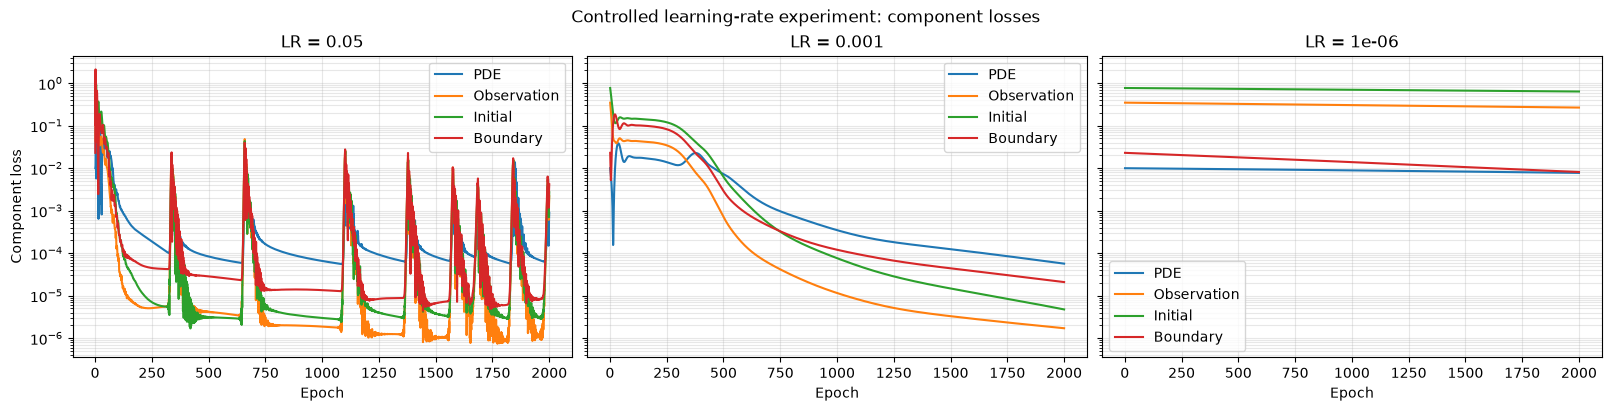

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True, layout="constrained")

for ax, learning_rate in zip(axes, learning_rates):
    history = lr_results[learning_rate]["history"]
    epochs_axis = np.arange(1, len(history["Total"]) + 1)
    for name in ("PDE", "Observation", "Initial", "Boundary"):
        ax.semilogy(epochs_axis, history[name], label=name)
    ax.set_xlabel("Epoch")
    ax.set_title(f"LR = {learning_rate:g}")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Component loss")
fig.suptitle("Controlled learning-rate experiment: component losses")
plt.show()

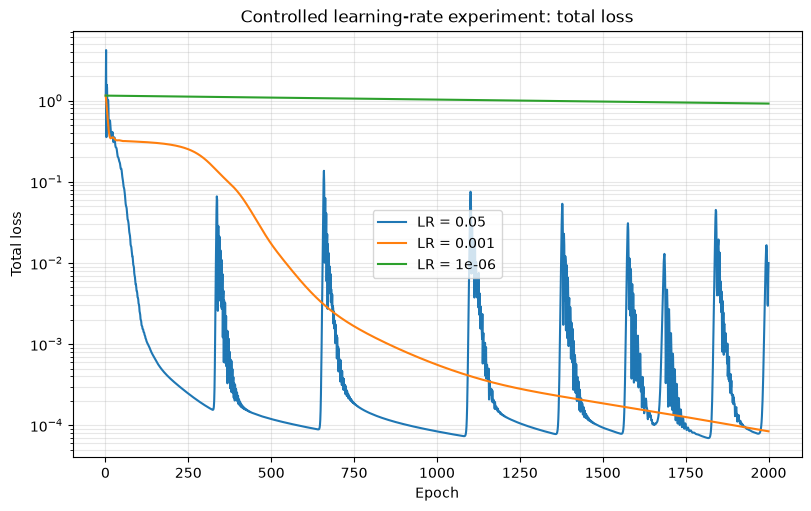

In [28]:
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")

for learning_rate in learning_rates:
    total_history = lr_results[learning_rate]["history"]["Total"]
    ax.semilogy(
        np.arange(1, len(total_history) + 1),
        total_history,
        label=f"LR = {learning_rate:g}",
    )

ax.set_xlabel("Epoch")
ax.set_ylabel("Total loss")
ax.set_title("Controlled learning-rate experiment: total loss")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

In [29]:
# One fixed space-time grid for all three final models.
x_eval = np.linspace(0, 1, 101)
t_eval = np.linspace(0, 1, 101)
X_eval, T_eval = np.meshgrid(x_eval, t_eval)
xt_eval_t = torch.tensor(
    np.column_stack((X_eval.ravel(), T_eval.ravel())),
    dtype=xt_obs_t.dtype,
    device=xt_obs_t.device,
)
u_exact_eval_t = torch.tensor(
    u_exact(X_eval, T_eval).reshape(-1, 1),
    dtype=xt_obs_t.dtype,
    device=xt_obs_t.device,
)

relative_l2_errors = {}
for learning_rate in learning_rates:
    trained_model = lr_results[learning_rate]["model"]
    trained_model.eval()
    # No derivatives are needed when comparing temperature values.
    with torch.no_grad():
        u_pred_eval = trained_model(xt_eval_t)
        relative_l2 = (
            torch.linalg.vector_norm(u_pred_eval - u_exact_eval_t)
            / torch.linalg.vector_norm(u_exact_eval_t)
        )
    relative_l2_errors[learning_rate] = relative_l2.item()
    print(f"LR = {learning_rate:g} | relative L2 error = {relative_l2.item():.6e}")

LR = 0.05 | relative L2 error = 8.965341e-02
LR = 0.001 | relative L2 error = 3.823505e-03
LR = 1e-06 | relative L2 error = 1.128874e+00
